In [57]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import os

In [58]:
# Membaca dataset hasil pelabelan final yang sudah dalam format long
file_path = '../data/annotations/dataset_labelled.xlsx'
df = pd.read_excel(file_path)

# Menampilkan informasi struktur tabel dan tipe data
df.info()
df_awal = df.copy()


<class 'pandas.DataFrame'>
RangeIndex: 6016 entries, 0 to 6015
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   No        6016 non-null   int64
 1   Ulasan    6016 non-null   str  
 2   Aspek     6016 non-null   str  
 3   Sentimen  6016 non-null   str  
dtypes: int64(1), str(3)
memory usage: 892.2 KB


In [59]:
# Membuang baris yang memiliki nilai kosong pada kolom esensial
df.dropna(subset=['Ulasan', 'Aspek', 'Sentimen'], inplace=True)

# Menyeragamkan penulisan teks pada kolom kategori untuk menghindari duplikasi ambigu
df['Sentimen'] = df['Sentimen'].astype(str).str.strip().str.capitalize()
df['Aspek'] = df['Aspek'].astype(str).str.strip().str.upper()

# Memastikan hanya label sentimen yang sah yang akan diproses
valid_sentiments = ['Positif', 'Negatif', 'Netral']
df = df[df['Sentimen'].isin(valid_sentiments)]

# Menghapus duplikasi baris yang memiliki ulasan dan aspek yang sama persis
df.drop_duplicates(subset=['Ulasan', 'Aspek'], keep='first', inplace=True)

print(f"Total baris data bersih setelah preprocessing: {len(df)}")

Total baris data bersih setelah preprocessing: 5985


In [60]:
df_kosong = df_awal[df_awal['Ulasan'].isna() | df_awal['Aspek'].isna() | df_awal['Sentimen'].isna()]
sentimen_aneh = df_awal[~df_awal['Sentimen'].astype(str).str.strip().str.capitalize().isin(valid_sentiments)]
df_duplikat = df_awal[df_awal.duplicated(subset=['Ulasan', 'Aspek'], keep='first')]

print(f"Dihapus karena ada kolom kosong: {len(df_kosong)} baris")
print(f"Dihapus karena sentimen tidak valid (misal: typo/kosong): {len(sentimen_aneh)} baris")
print(f"Dihapus karena ulasan & aspek duplikat: {len(df_duplikat)} baris")

Dihapus karena ada kolom kosong: 0 baris
Dihapus karena sentimen tidak valid (misal: typo/kosong): 0 baris
Dihapus karena ulasan & aspek duplikat: 31 baris


In [61]:
ulasan_duplikat = df_awal[df_awal.duplicated(subset=['Ulasan', 'Aspek'], keep=False)]
ulasan_duplikat_sorted = ulasan_duplikat.sort_values(by=['Ulasan', 'Aspek'])
ulasan_duplikat_sorted[['Ulasan', 'Aspek', 'Sentimen']].head(20)

,Ulasan,Aspek,Sentimen
121,bagus,A3,Positif
122,bagus,A3,Positif
5179,banyak hal yang kurang memuaskan dari awal sam...,A2,Netral
5180,banyak hal yang kurang memuaskan dari awal sam...,A2,Negatif
22,barang sesuai deskripsi packing mantap cuma pe...,C1,Positif
23,barang sesuai deskripsi packing mantap cuma pe...,C1,Negatif
1098,biasa saja overall tidak ada yang spesial saya...,A3,Positif
1099,biasa saja overall tidak ada yang spesial saya...,A3,Netral
2794,buram saat gerak cepat tingkat kecerahan layar...,A1,Positif
2795,buram saat gerak cepat tingkat kecerahan layar...,A1,Negatif


In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

C:\Users\TECNO\AppData\Local\Temp\ipykernel_10200\45266549.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(


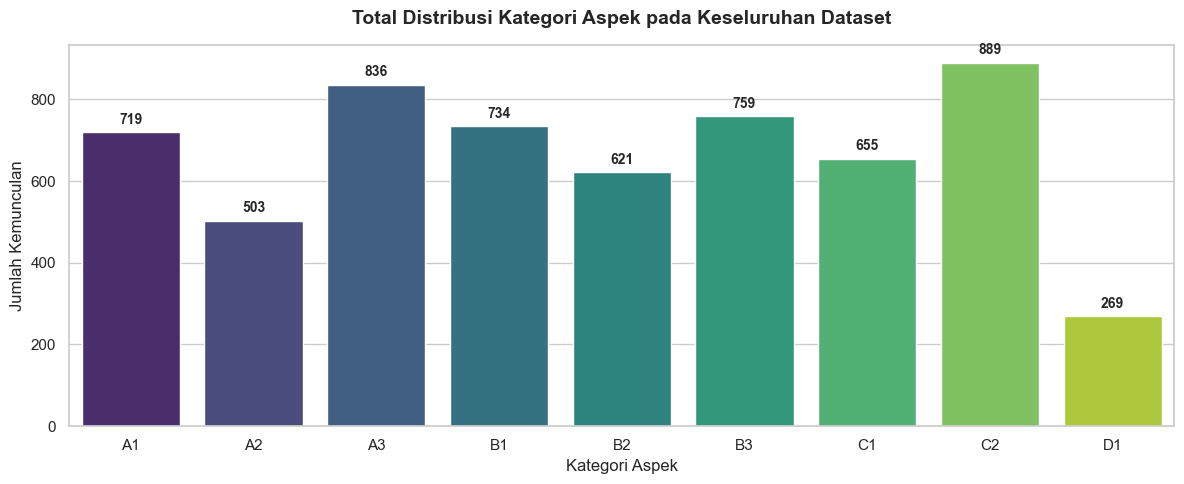

In [63]:
# Menampilkan total kemunculan setiap kategori aspek di keseluruhan dataset
plt.figure(figsize=(12, 5))
urutan_aspek = sorted(df['Aspek'].unique())

ax1 = sns.countplot(
    x='Aspek', 
    data=df, 
    order=urutan_aspek, 
    palette='viridis'
)

plt.title('Total Distribusi Kategori Aspek pada Keseluruhan Dataset', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Aspek', fontsize=12)
plt.ylabel('Jumlah Kemunculan', fontsize=12)

# Menambahkan anotasi angka pasti di atas masing-masing batang grafik
for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(f'{int(height)}', 
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold',
                     xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

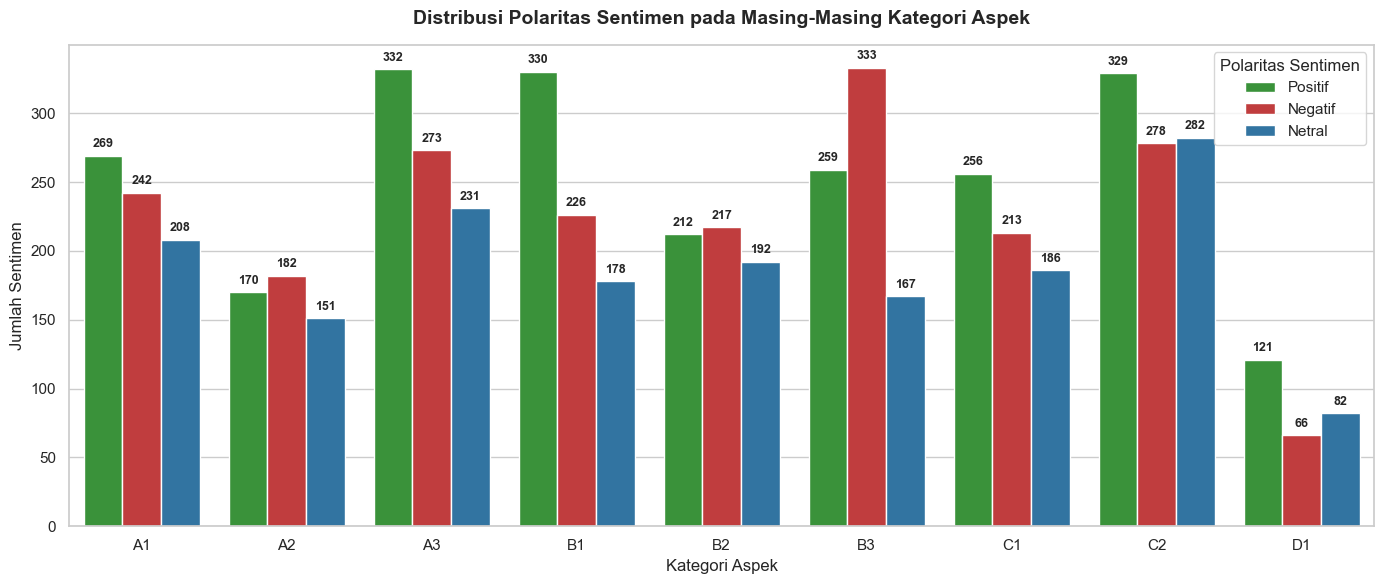

In [64]:
# Memecah lumlah aspek berdasarkan kategori sentimen yang melekat
plt.figure(figsize=(14, 6))

warna_sentimen = {
    'Positif': '#2ca02c', 
    'Negatif': '#d62728', 
    'Netral': '#1f77b4'   
}

ax2 = sns.countplot(
    x='Aspek', 
    hue='Sentimen', 
    data=df, 
    order=urutan_aspek,
    hue_order=['Positif', 'Negatif', 'Netral'],
    palette=warna_sentimen
)

plt.title('Distribusi Polaritas Sentimen pada Masing-Masing Kategori Aspek', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Aspek', fontsize=12)
plt.ylabel('Jumlah Sentimen', fontsize=12)
plt.legend(title='Polaritas Sentimen', loc='upper right')

# Menambahkan anotasi angka pasti di atas setiap batang sentimen
for p in ax2.patches:
    height = p.get_height()
    # Memastikan tidak ada error saat batang bernilai kosong (NaN)
    if not np.isnan(height) and height > 0:
        ax2.annotate(f'{int(height)}', 
                     (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=9, fontweight='bold',
                     xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

In [65]:
# Menampilkan 5 ulasan teratas untuk setiap kombinasi Kategori Aspek dan Sentimen
kombinasi_aspek_sentimen = df.groupby(['Aspek', 'Sentimen'])

print("INSPEKSI SAMPEL ULASAN PER KATEGORI DAN SENTIMEN\n" + "="*70)

for nama_grup, grup_df in kombinasi_aspek_sentimen:
    aspek, sentimen = nama_grup
    print(f"\n[ Kategori Aspek: {aspek} | Sentimen: {sentimen} | Total Baris: {len(grup_df)} ]")
    print("-" * 70)
    
    sampel_ulasan = grup_df['Ulasan'].head(5).tolist()
    
    for i, teks in enumerate(sampel_ulasan, 1):
        print(f"{i}. {teks}")

INSPEKSI SAMPEL ULASAN PER KATEGORI DAN SENTIMEN

[ Kategori Aspek: A1 | Sentimen: Negatif | Total Baris: 242 ]
----------------------------------------------------------------------
1. layar terlihat buram contrast yang tinggi nya jauh dari klaim penjual tapi pengalaman belanja yang menyenangkan secara keseluruhan
2. sayang sekali refresh rate rate 165 Hz nya tidak sesuai deskripsi seperti di foto kurang puas jujur
3. kecewa berat warnanya pucat refresh rate 165 Hz nya meleset dari ekspektasi semoga diperbaiki ya
4. refresh rate rate 100 Hz ya tidak sesuai deskripsi seperti di foto kurang puas jujur
5. warnanya pucat refresh rate 100 Hz nya meleset dari ekspektasi hanya saja pokoknya mantap belanja di sini

[ Kategori Aspek: A1 | Sentimen: Netral | Total Baris: 208 ]
----------------------------------------------------------------------
1. untuk pemakaian harian tampilan FHD nya cukup lumayan tapi ternyata lebih mahal dari kompetitor sekelasnya
2. secara umum refresh rate rate 165 Hz 

In [66]:
df_unique = df.groupby('Ulasan')['Sentimen'].agg(lambda x: x.mode()[0]).reset_index()

ulasan_unik = df_unique['Ulasan'].tolist()
stratify_labels = df_unique['Sentimen'].tolist()

print(f"Total entitas ulasan unik sebelum pembagian: {len(ulasan_unik)}")

# Membagi ulasan unik dengan stratifikasi berbasis sentimen (80:20)
train_ulasan, temp_ulasan, train_labels, temp_labels = train_test_split(
    ulasan_unik, stratify_labels, test_size=0.2, random_state=42, stratify=stratify_labels
)

# Membagi sisa ulasan menjadi rasio yang sama (10% validasi, 10% uji)
val_ulasan, test_ulasan = train_test_split(
    temp_ulasan, test_size=0.5, random_state=42, stratify=temp_labels
)

# Memetakan kembali ulasan unik yang telah dibagi ke dalam format dataset utuh (Long Format)
df_train = df[df['Ulasan'].isin(train_ulasan)].copy()
df_val = df[df['Ulasan'].isin(val_ulasan)].copy()
df_test = df[df['Ulasan'].isin(test_ulasan)].copy()

# Mereset indeks pada masing-masing himpunan data agar terstruktur
df_train.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

print(f"\nDistribusi Baris Akhir (Long Format):")
print(f"Data Latih (Train)  : {len(df_train)} baris")
print(f"Data Validasi (Val) : {len(df_val)} baris")
print(f"Data Uji (Test)     : {len(df_test)} baris")

# Menyiapkan direktori penyimpanan dan menyimpan hasil pembagian data ke dalam format CSV
output_dir = '../data/splits'
os.makedirs(output_dir, exist_ok=True)

df_train.to_csv(f'{output_dir}/train.csv', index=False)
df_val.to_csv(f'{output_dir}/val.csv', index=False)
df_test.to_csv(f'{output_dir}/test.csv', index=False)

Total entitas ulasan unik sebelum pembagian: 3324

Distribusi Baris Akhir (Long Format):
Data Latih (Train)  : 4794 baris
Data Validasi (Val) : 603 baris
Data Uji (Test)     : 588 baris


In [67]:
def plot_distribusi_split_stacked(df_split, judul_grafik):
    df_grouped = pd.crosstab(df_split['Aspek'], df_split['Sentimen'])
    
    urutan_aspek = sorted(df_split['Aspek'].dropna().unique())
    df_grouped = df_grouped.reindex(index=urutan_aspek, fill_value=0)
    
    urutan_sentimen = ['Positif', 'Negatif', 'Netral']
    warna_sentimen = {'Positif': '#2ca02c', 'Negatif': '#d62728', 'Netral': '#1f77b4'}
    
    kolom_tersedia = [s for s in urutan_sentimen if s in df_grouped.columns]
    df_grouped = df_grouped[kolom_tersedia]
    warna_plot = [warna_sentimen[s] for s in kolom_tersedia]
    
    # Konfigurasi plot
    plt.figure(figsize=(14, 6))
    sns.set_theme(style="whitegrid")
    
    # Membuat grafik batang bertumpuk 
    ax = df_grouped.plot(
        kind='bar', 
        stacked=True, 
        color=warna_plot, 
        figsize=(14, 6),
        width=0.7
    )
    
    plt.title(judul_grafik, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Kategori Aspek', fontsize=12)
    plt.ylabel('Jumlah Kemunculan', fontsize=12)
    plt.legend(title='Polaritas Sentimen', loc='upper right')
    plt.xticks(rotation=0)
    
    # Menambahkan anotasi angka di tengah masing-masing blok tumpukan
    for p in ax.patches:
        lebar = p.get_width()
        tinggi = p.get_height()
        x, y = p.get_xy()
        
        # Hanya menampilkan angka jika ada data pada blok tersebut
        if tinggi > 0:
            ax.text(
                x + lebar / 2, 
                y + tinggi / 2, 
                int(tinggi), 
                ha='center', 
                va='center', 
                color='white', 
                fontweight='bold',
                fontsize=10
            )
            
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

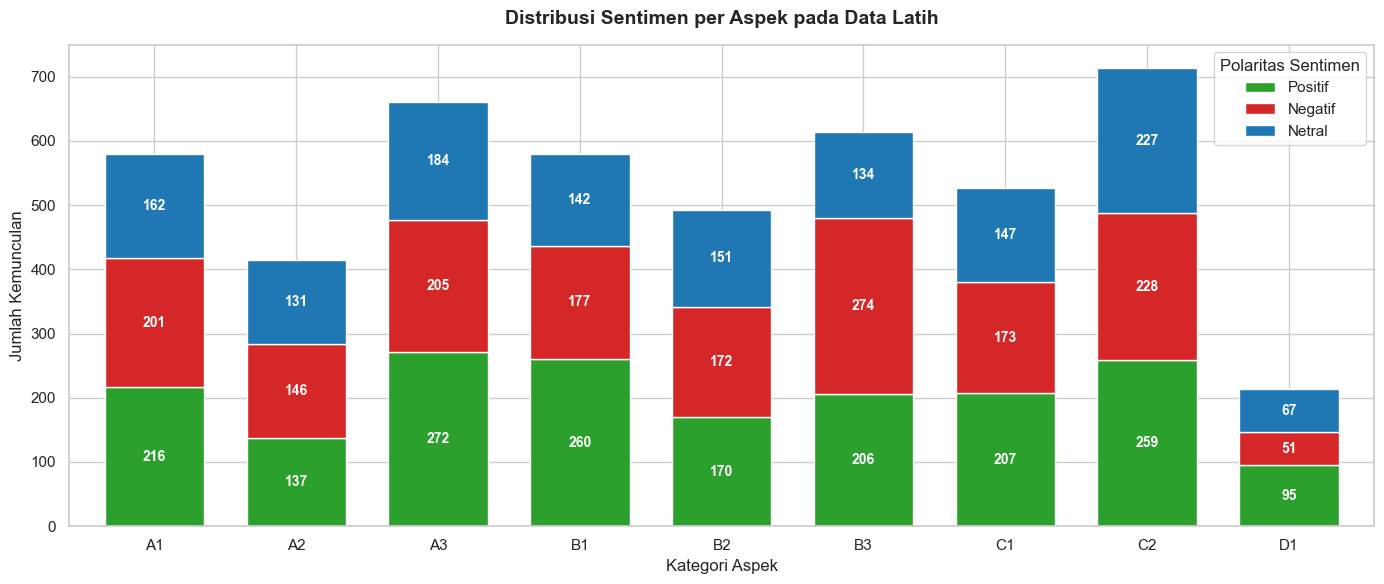

In [68]:
plot_distribusi_split_stacked(df_train, 'Distribusi Sentimen per Aspek pada Data Latih')

<Figure size 1400x600 with 0 Axes>

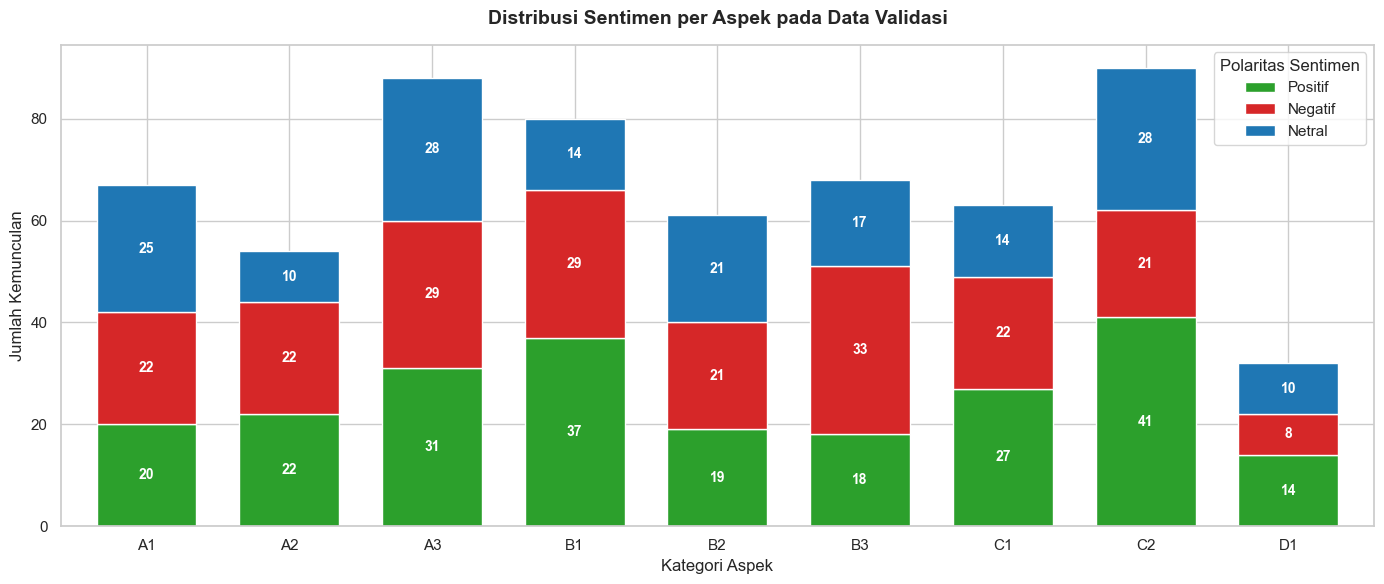

In [69]:
# Menampilkan grafik Stacked Bar khusus untuk Data Validasi 
plot_distribusi_split_stacked(df_val, 'Distribusi Sentimen per Aspek pada Data Validasi')

<Figure size 1400x600 with 0 Axes>

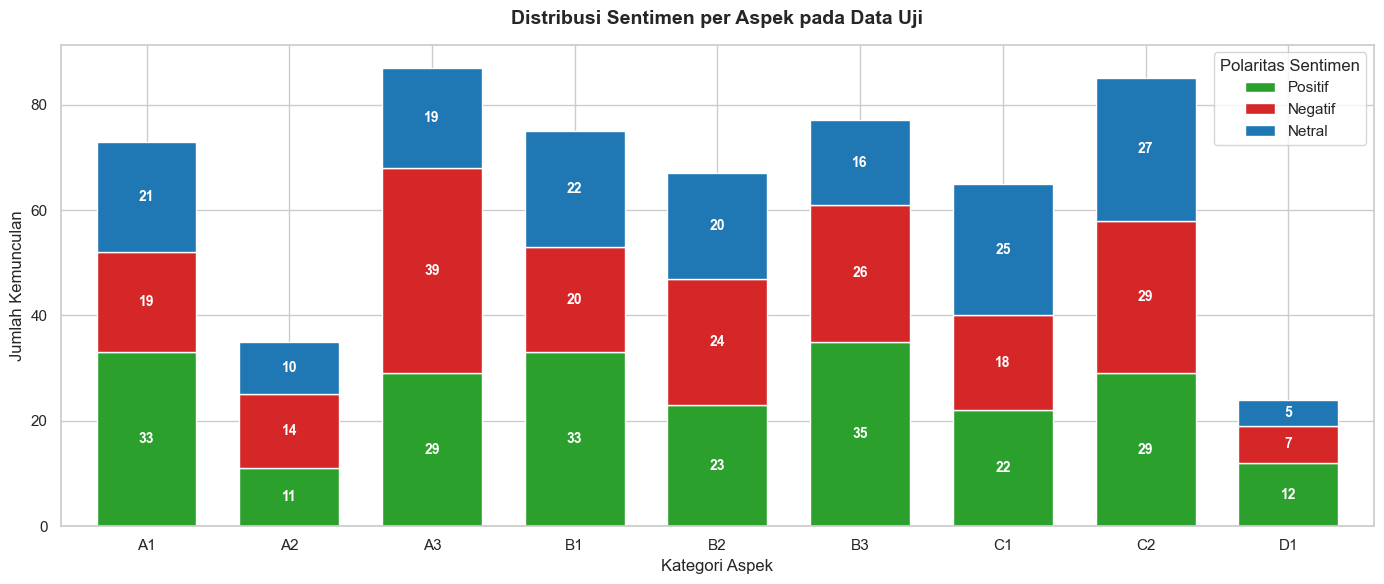

In [70]:
plot_distribusi_split_stacked(df_test, 'Distribusi Sentimen per Aspek pada Data Uji')